<a href="https://colab.research.google.com/github/martinezfredy33/infografia/blob/main/Flujo_completo_de_clasificaci%C3%B3n_supervisada_(binaria_y_multiclase).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Configuración de Entorno e Importación

Nombre de la Tarea en Moodle: R2-A2-S11 RESOLUCIÓN DE EJERCICIOS.

Estudiante: Fredy Martínez Rodríguez

Gestor de conocimiento: Docente Nidia García


### 1. Importación de Librerías y Datasets Nativos

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# Algoritmos de clasificación supervisada
from sklearn.ensemble import RandomForestClassifier # Bosques Aleatorios

# Carga de datasets nativos de Scikit-learn
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.linear_model import LogisticRegression # Regresión Logística

# Métricas de evaluación y visualización
# Necesarias para medir, diagnosticar y visualizar la casificación de los modelos
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.neighbors import KNeighborsClassifier # K-Vecinos más Cercanos
from sklearn.pipeline import Pipeline

# Preprocesamiento y partición
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier # Árbol de Decisión

Análisis e Interpretación Técnica:

Propósito: Cargar los módulos para manipulación tabular (pandas), cálculo numérico (numpy), gráficos (matplotlib), división estratificada de datos, estandarización de escala, encadenamiento en Pipeline y algoritmos de clasificación.

Punto Clave: Los conjuntos de datos load_breast_cancer y load_iris están integrados en sklearn.datasets, asegurando un entorno reproducible sin necesidad de manipular archivos CSV externos.

## Clasificación Binaria (load_breast_cancer)

### 2. Carga e Inspección de la Variable Objetivo

In [29]:
# Carga del dataset en formato DataFrame
datos = load_breast_cancer(as_frame=True)
X = datos.data
y = datos.target
print('Dimensión de la matriz de características X:', X.shape)
print('Etiquetas de las clases:', datos.target_names)
print('\nDistribución de la variable objetivo:')
print(y.value_counts())

Dimensión de la matriz de características X: (569, 30)
Etiquetas de las clases: ['malignant' 'benign']

Distribución de la variable objetivo:
target
1    357
0    212
Name: count, dtype: int64


Análisis e interpretación técnica:

Estructura: El conjunto de datos consta de 569 observaciones y 30 variables predictoras de naturaleza cuantitativa.

Mapeo de clases: La etiqueta 0 corresponde a tumores malignos con 212 casos registrados, mientras que la etiqueta 1 representa tumores benignos con un total de 357 casos.

Importancia clínica: Verificar el significado de cada clase previene invertir por error las métricas de sensibilidad y precisión durante la evaluación diagnóstica del modelo.

## 3. Partición del Conjunto de Datos (Train / Test Split)

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Entrenamiento (80%):", X_train.shape)
print("Prueba (20%):", X_test.shape)

Entrenamiento (80%): (455, 30)
Prueba (20%): (114, 30)


Análisis e interpretación técnica:

Distribución: Se asignan 455 registros al conjunto de entrenamiento y 114 al conjunto de prueba.

Estratificación: El parámetro stratify conserva la proporción original de las clases en ambos subconjuntos, garantizando una validación representativa y sin sesgos estructurales.

## 4. Configuración de Pipelines, Entrenamiento y Evaluación Comparativa

In [31]:
modelos = {
    "Regresión logística": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42)),
    ]),
    "K-NN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5)),
    ]),
    "Árbol de decisión": DecisionTreeClassifier(
        max_depth=4, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    ),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        (
            "model",
            SVC(kernel="rbf", probability=True, random_state=42),
        ),
    ]),
}

resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

tabla_binaria = pd.DataFrame(resultados).sort_values("F1", ascending=False)
display(tabla_binaria)

,Modelo,Accuracy,Precision,Recall,F1
0,Regresión logística,0.982456,0.986111,0.986111,0.986111
4,SVM,0.982456,0.986111,0.986111,0.986111
1,K-NN,0.956140,0.958904,0.972222,0.965517
3,Random Forest,0.956140,0.958904,0.972222,0.965517
2,Árbol de decisión,0.938596,0.957746,0.944444,0.951049


Análisis e interpretación técnica:

Estandarización: El uso de herramientas como StandardScaler evita que variables con escalas numéricas amplias dominen el entrenamiento en modelos basados en distancias, como K-NN y SVM, o en optimización por gradiente, como la Regresión Logística.

Métricas: Los clasificadores alcanzan un rendimiento global con valores de exactitud y puntaje F1 entre el 94% y el 98%. En el ámbito médico, la prioridad analítica se centra en la sensibilidad (Recall) sobre la clase de tumores malignos, lo que permite minimizar la incidencia de falsos negativos en el diagnóstico.

## 5. Matriz de Confusión y Análisis de Umbral

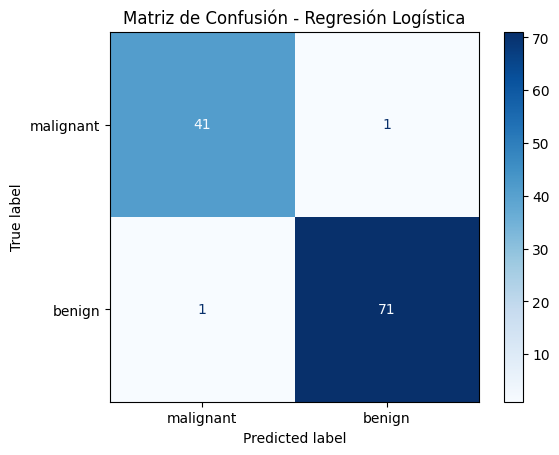

,Real,Probabilidad_Benigno,Prediccion_Umbral_0.5
0,0,5.888242e-08,0
1,1,9.999887e-01,1
2,0,6.410825e-03,0
3,1,5.335085e-01,1
4,0,6.525001e-10,0
5,1,9.921604e-01,1
6,1,9.999828e-01,1
7,0,5.635275e-07,0
8,0,5.431637e-05,0
9,0,8.041849e-11,0


In [32]:
# Evaluación del modelo de Regresión Logística
modelo_final = modelos['Regresión logística']
modelo_final.fit(X_train, y_train)
pred_final = modelo_final.predict(X_test)

# Matriz de Confusión
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_final, display_labels=datos.target_names, cmap='Blues'
)
plt.title('Matriz de Confusión - Regresión Logística')
plt.show()

# Probabilidades continuas y umbral
probabilidades = modelo_final.predict_proba(X_test)[:, 1]
ejemplo_prob = pd.DataFrame({
    'Real': y_test.values[:10],
    'Probabilidad_Benigno': probabilidades[:10],
    'Prediccion_Umbral_0.5': (probabilidades[:10] >= 0.5).astype(int),
})
display(ejemplo_prob)

Análisis e interpretación técnica:

La matriz de confusión concentra los aciertos en su diagonal principal. Modificar el umbral estándar de cero punto cinco permite calibrar la sensibilidad del modelo diagnóstico en función del impacto clínico que implica cometer un falso negativo.

# Clasificación Multiclase (load_iris)

## 6. Clasificación de Tres Especies de Flores

In [33]:
iris = load_iris(as_frame=True)
X_iris, y_iris = iris.data, iris.target
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_iris,
    y_iris,
    test_size=0.25,
    random_state=42,
    stratify=y_iris,
)

modelos_multi = {
    "Regresión logística": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42)),
    ]),
    "K-NN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5)),
    ]),
    "Árbol": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    ),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", random_state=42)),
    ]),
}

resultados_multi = []
for nombre, modelo in modelos_multi.items():
    modelo.fit(Xi_train, yi_train)
    pred = modelo.predict(Xi_test)
    resultados_multi.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(yi_test, pred),
        "F1_macro": f1_score(yi_test, pred, average="macro"),
    })

tabla_multi = pd.DataFrame(resultados_multi).sort_values(
    "F1_macro", ascending=False
)
display(tabla_multi)

,Modelo,Accuracy,F1_macro
4,SVM,0.947368,0.948718
0,Regresión logística,0.921053,0.922963
2,Árbol,0.921053,0.922963
1,K-NN,0.921053,0.922039
3,Random Forest,0.894737,0.896825


Análisis e interpretación técnica:

Evaluación multiclase: La métrica F1 macro calcula el rendimiento promedio para cada una de las tres especies del conjunto de datos.

Separabilidad geométrica: La especie Iris setosa se separa de manera totalmente lineal, mientras que los errores de clasificación se concentran entre versicolor y virginica debido al solapamiento natural en las dimensiones de sus pétalos.

# Contraste con Aprendizaje No Supervisado (Clustering)

## 7. Comparación con K-Means

In [34]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_iris)
comparacion = pd.DataFrame({
    "Clase_Real": y_iris.map(dict(enumerate(iris.target_names))),
    "Cluster_Descubierto": clusters,
})
display(
    pd.crosstab(
        comparacion["Clase_Real"], comparacion["Cluster_Descubierto"]
    )
)

Cluster_Descubierto,0,1,2
Clase_Real,,,
setosa,0,50,0
versicolor,48,0,2
virginica,14,0,36


Análisis e interpretación técnica:

Diferencia fundamental: El algoritmo K-Means agrupa las observaciones basándose únicamente en la proximidad geométrica de las variables predictoras, sin intervención previa de la etiqueta objetivo.

Asignación de grupos: Las etiquetas numéricas de los clústeres descubiertos no coinciden de manera directa con los nombres reales de las especies biológicas, lo que evidencia la distinción metodológica entre el aprendizaje supervisado y el aprendizaje no supervisado orientado al descubrimiento de estructuras latentes.

## Conclusiones